# Smog City – Week 4: EDA Deep Dive

**Dataset used:** `aqi_india_38cols_knn_final.csv`  
**Project:** Smog City – Visualizing the Invisible Threat

### Week 4 requirements
- Univariate analysis
- Bivariate analysis
- Data distributions
- City-wise comparison
- Time/season analysis
- Correlation analysis

> This notebook is updated for the actual CSV in your ZIP file. It does **not** use `city_day.csv`.


## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Upload the Dataset

From your ZIP, use:

**`aqi_india_38cols_knn_final.csv`**

Upload that CSV to Colab when prompted.


In [ ]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("File:", file_name)


Saving aqi_india_38cols_knn_final.csv to aqi_india_38cols_knn_final.csv
Dataset loaded successfully!
File: aqi_india_38cols_knn_final.csv


## 3. Understand the Dataset

In [ ]:
df.head()


,city,state,latitude,longitude,datetime,month,day_name,is_weekend,season,time_of_day,...,no2_ugm3,so2_ugm3,o3_ugm3,dust_ugm3,aod,us_aqi,aqi_category,pm25_category_india,festival_period,crop_burning_season
0,agartala,tripura,23.8315,91.2868,2022-08-05 00:00:00,8.0,friday,False,monsoon,night,...,21.8,2.7,32.0,0.0,0.14,289.0,Very Unhealthy,good,False,False
1,agartala,tripura,23.8315,91.2868,2022-08-05 01:00:00,8.0,friday,False,monsoon,night,...,18.5,3.0,33.0,0.0,0.14,289.0,Very Unhealthy,good,False,False
2,agartala,tripura,23.8315,91.2868,2022-08-05 02:00:00,8.0,friday,False,monsoon,night,...,15.1,3.3,34.0,0.0,0.15,54.0,Moderate,good,False,False
3,agartala,tripura,23.8315,91.2868,2022-08-05 03:00:00,8.0,friday,False,monsoon,night,...,14.1,3.3,32.0,0.0,0.15,54.0,Moderate,good,False,False
4,agartala,tripura,23.8315,91.2868,2022-08-05 04:00:00,8.0,friday,False,monsoon,night,...,13.9,3.2,30.0,0.0,0.14,54.0,Moderate,good,False,False


In [ ]:
print("Rows and columns:", df.shape)


Rows and columns: (842160, 31)


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842160 entries, 0 to 842159
Data columns (total 31 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   city                 842160 non-null  object 
 1   state                842160 non-null  object 
 2   latitude             842160 non-null  float64
 3   longitude            842160 non-null  float64
 4   datetime             842160 non-null  object 
 5   month                842160 non-null  float64
 6   day_name             842160 non-null  object 
 7   is_weekend           842160 non-null  bool   
 8   season               842160 non-null  object 
 9   time_of_day          842160 non-null  object 
 10  humidity_percent     842160 non-null  float64
 11  dew_point_c          842160 non-null  float64
 12  wind_gusts_kmh       842160 non-null  float64
 13  precipitation_mm     842160 non-null  float64
 14  is_raining           842160 non-null  bool   
 15  heavy_rain       

In [ ]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
city,842160,29,agartala,29040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,842160,29,tripura,29040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,842160.0,NaN,NaN,NaN,23.129041,5.543478,8.5241,20.2961,23.8315,26.9124,31.1048
longitude,842160.0,NaN,NaN,NaN,82.769207,6.937205,72.5714,77.1734,80.9462,88.6065,94.1086
datetime,842160,29040,2025-11-26 07:00:00,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,842160.0,NaN,NaN,NaN,6.801653,3.411504,1.0,4.0,7.0,10.0,12.0
day_name,842160,7,friday,120408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_weekend,842160,2,False,601344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,842160,4,monsoon,294408,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_of_day,842160,6,night,210540,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Check Missing Values

In [ ]:
missing_values = df.isnull().sum().sort_values(ascending=False)
display(missing_values.to_frame("Missing Values"))


,Missing Values
pm25_category_india,2
state,0
city,0
longitude,0
datetime,0
month,0
latitude,0
is_weekend,0
season,0
time_of_day,0


# UNIVARIATE ANALYSIS

Univariate analysis studies **one variable at a time**.


## 5. US AQI Distribution

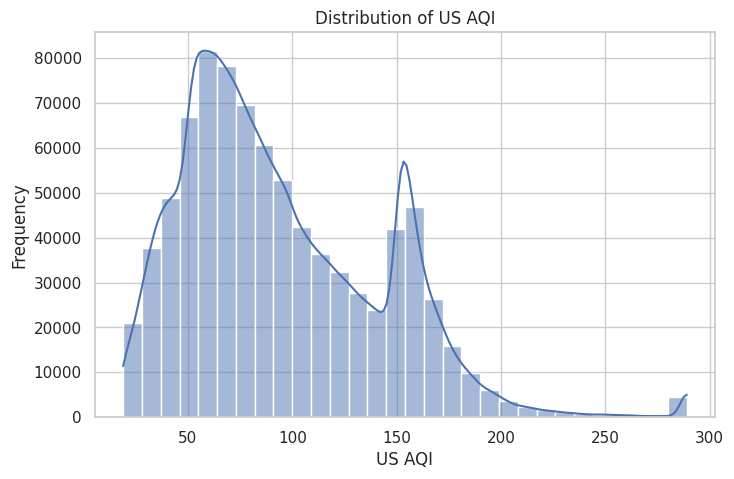

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["us_aqi"].dropna(), bins=30, kde=True)

plt.title("Distribution of US AQI")
plt.xlabel("US AQI")
plt.ylabel("Frequency")
plt.show()


## 6. US AQI Boxplot

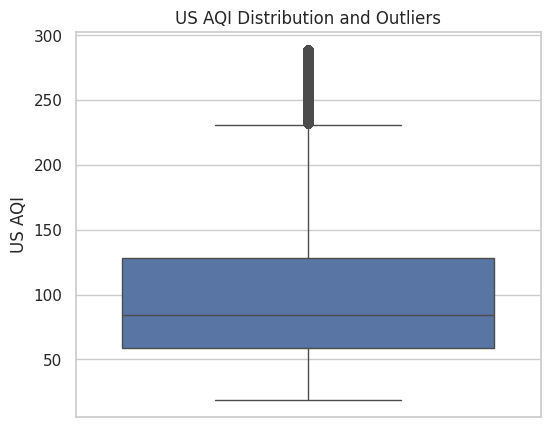

In [ ]:
plt.figure(figsize=(6, 5))

sns.boxplot(y=df["us_aqi"].dropna())

plt.title("US AQI Distribution and Outliers")
plt.ylabel("US AQI")
plt.show()


### Observation
The histogram shows the distribution of AQI values, while the boxplot shows the spread, median, and possible extreme values.


## 7. Pollutant Distributions

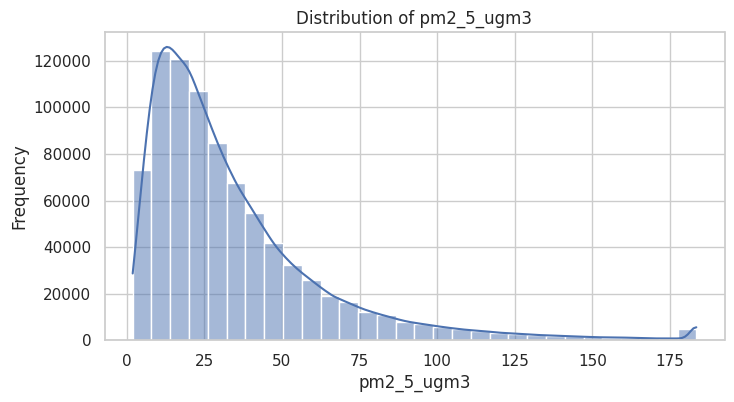

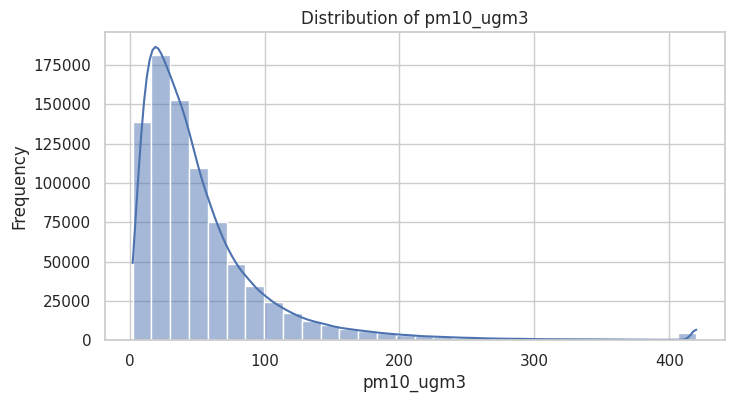

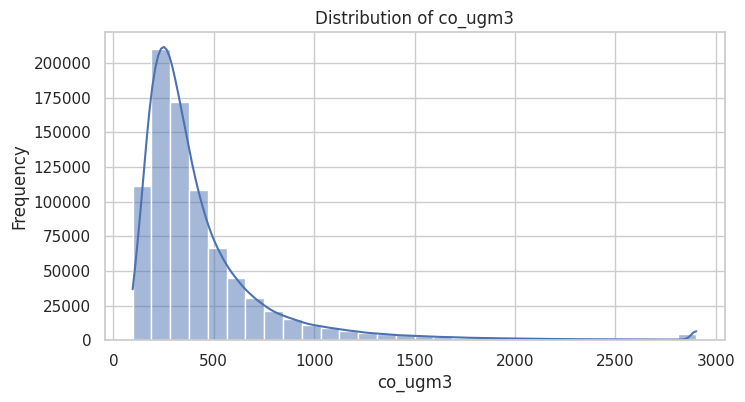

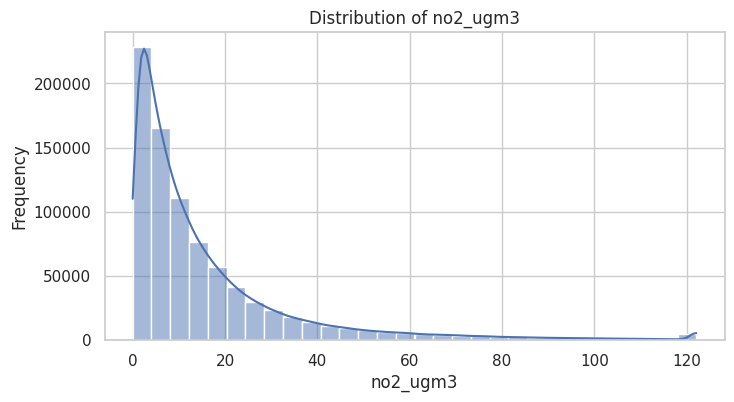

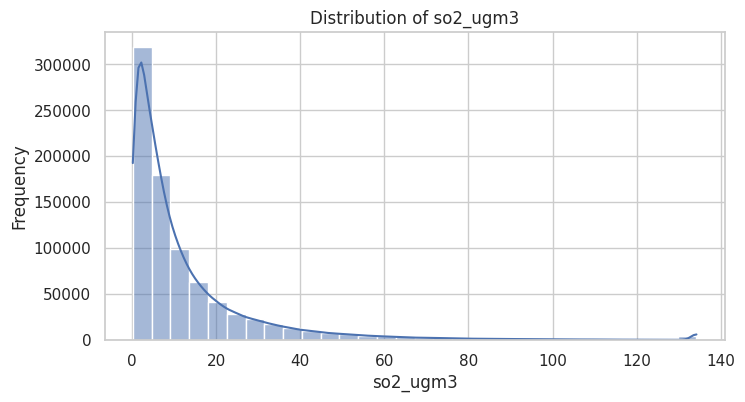

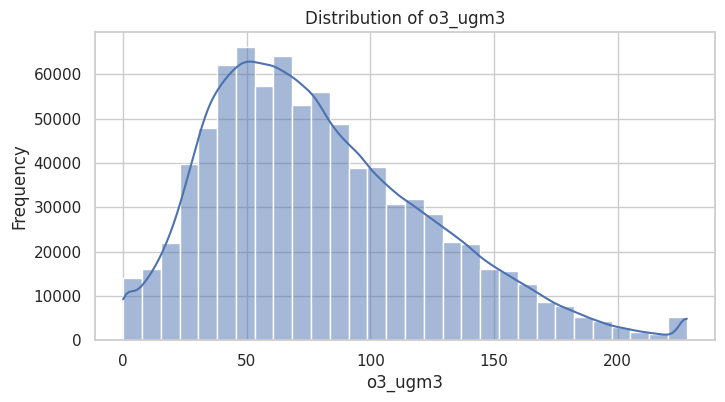

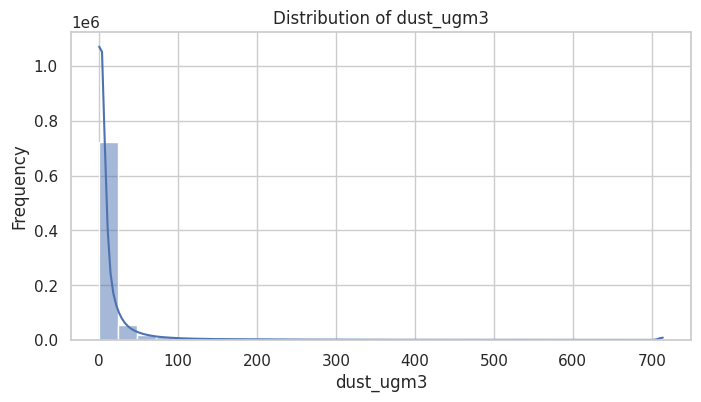

In [ ]:
pollutants = [
    "pm2_5_ugm3",
    "pm10_ugm3",
    "co_ugm3",
    "no2_ugm3",
    "so2_ugm3",
    "o3_ugm3",
    "dust_ugm3"
]

for pollutant in pollutants:
    if pollutant in df.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(df[pollutant].dropna(), bins=30, kde=True)
        plt.title(f"Distribution of {pollutant}")
        plt.xlabel(pollutant)
        plt.ylabel("Frequency")
        plt.show()


# BIVARIATE ANALYSIS

Bivariate analysis studies the relationship between **two variables**.


## 8. PM2.5 vs US AQI

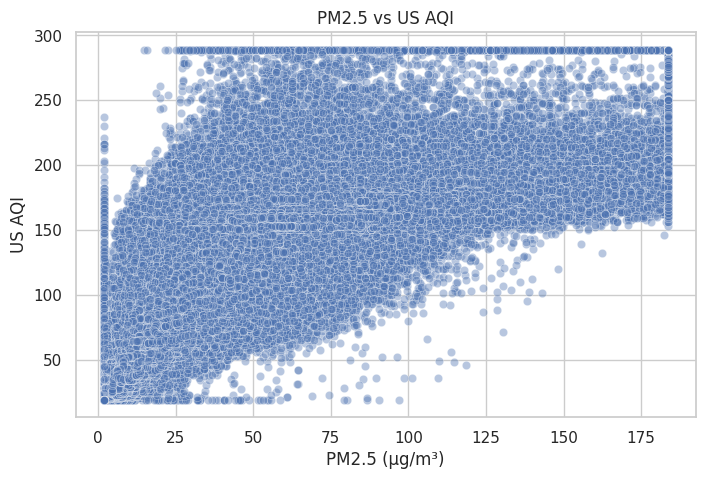

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="pm2_5_ugm3",
    y="us_aqi",
    alpha=0.4
)

plt.title("PM2.5 vs US AQI")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("US AQI")
plt.show()


## 9. Other Pollutants vs US AQI

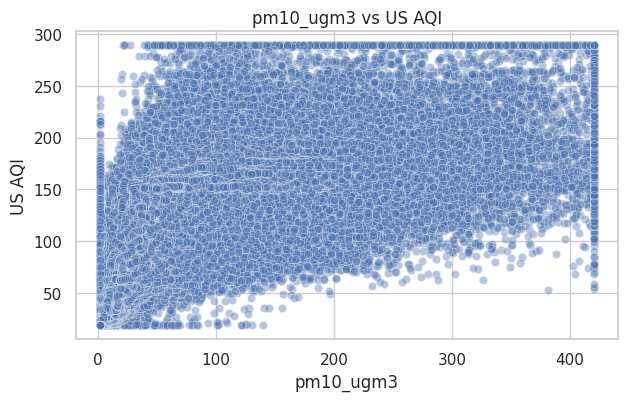

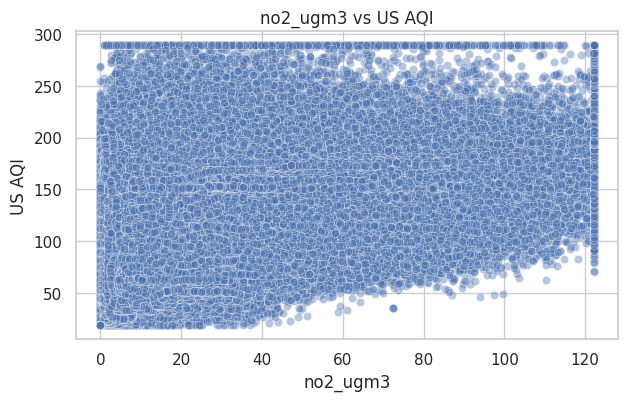

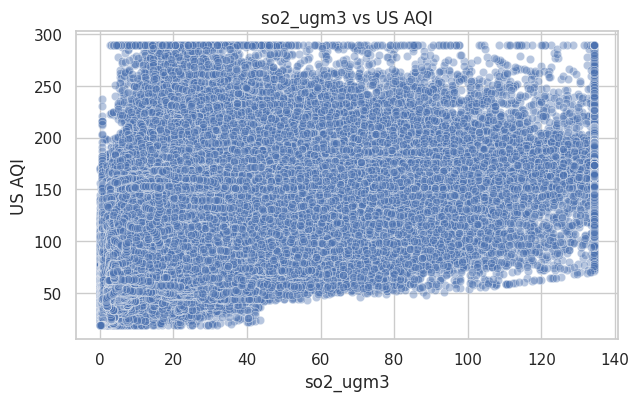

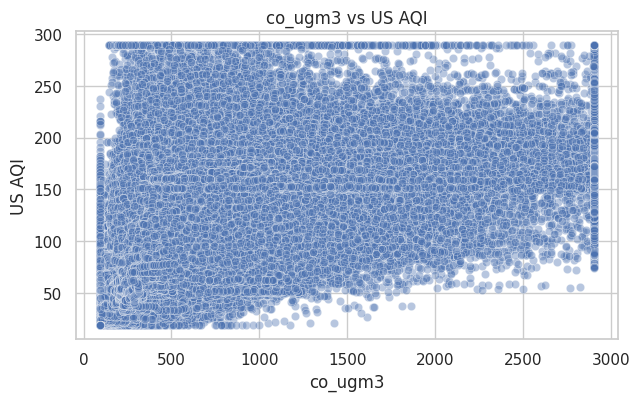

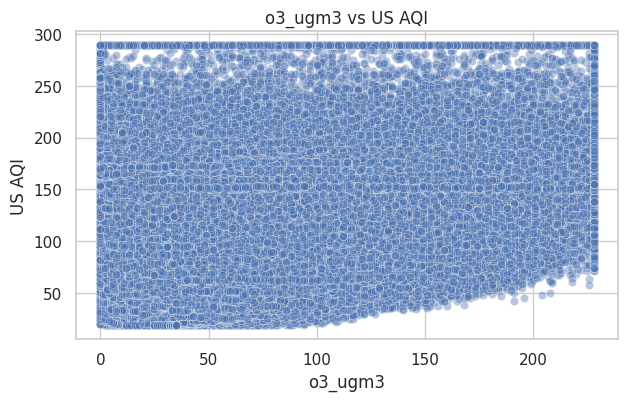

In [ ]:
for pollutant in ["pm10_ugm3", "no2_ugm3", "so2_ugm3", "co_ugm3", "o3_ugm3"]:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(
        data=df,
        x=pollutant,
        y="us_aqi",
        alpha=0.4
    )
    plt.title(f"{pollutant} vs US AQI")
    plt.xlabel(pollutant)
    plt.ylabel("US AQI")
    plt.show()


## 10. Correlation Heatmap

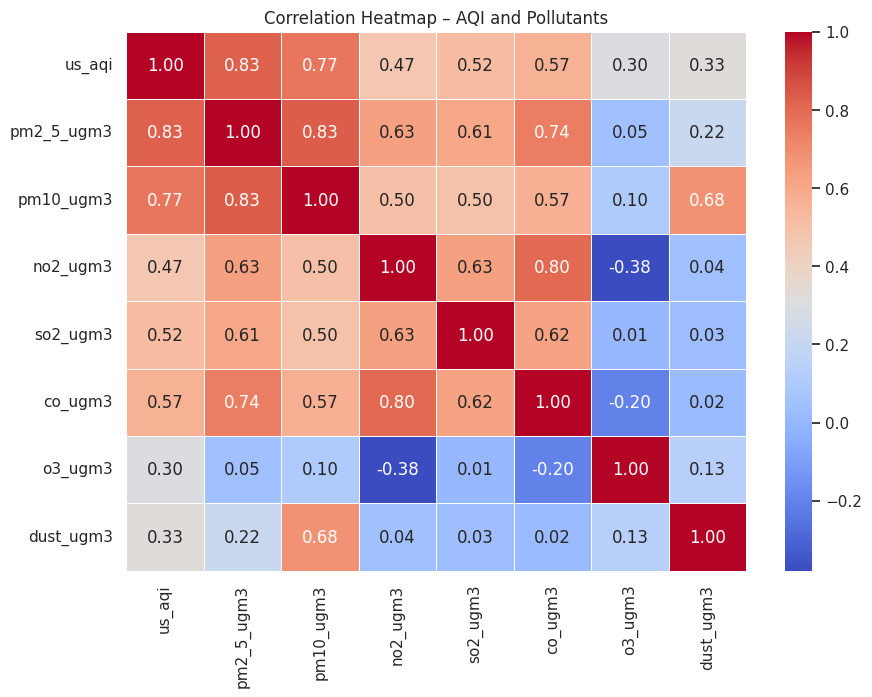

In [ ]:
analysis_columns = [
    "us_aqi",
    "pm2_5_ugm3",
    "pm10_ugm3",
    "no2_ugm3",
    "so2_ugm3",
    "co_ugm3",
    "o3_ugm3",
    "dust_ugm3"
]

correlation = df[analysis_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap – AQI and Pollutants")
plt.show()


### Observation
Correlation values closer to **+1** show stronger positive linear relationships, while values closer to **-1** show stronger negative relationships. Values near **0** indicate weaker linear relationships.

Correlation alone does not prove causation.


## 11. City-wise Average AQI

In [ ]:
city_aqi = (
    df.groupby("city")["us_aqi"]
      .mean()
      .sort_values(ascending=False)
)

display(city_aqi.head(10).to_frame("Average US AQI"))


,Average US AQI
city,
gurugram,166.606715
delhi,154.925551
patna,132.852445
lucknow,129.252359
raipur,123.701274
kolkata,122.432507
chandigarh,115.347004
mumbai,114.189222
agartala,105.542045


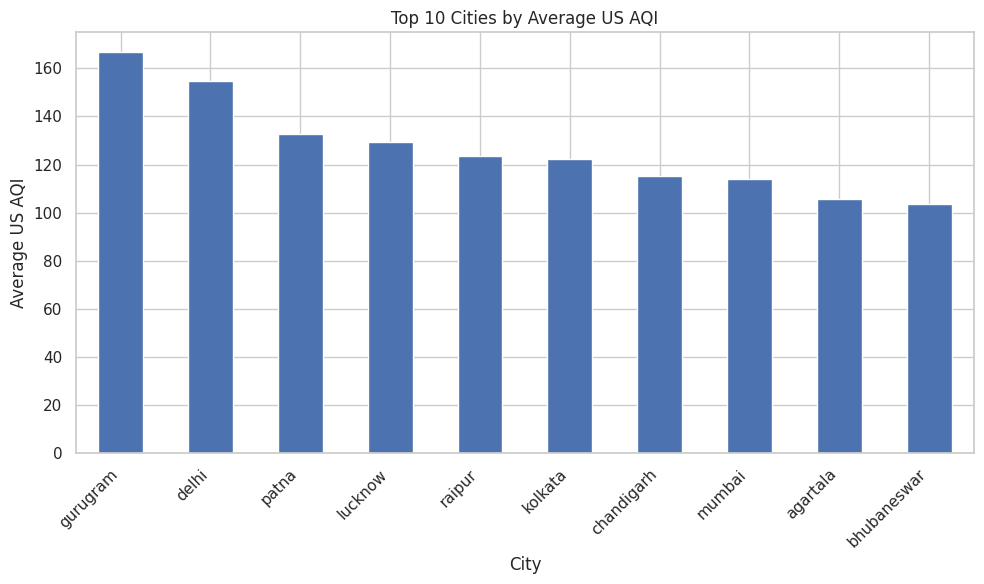

In [ ]:
plt.figure(figsize=(10, 6))

city_aqi.head(10).plot(kind="bar")

plt.title("Top 10 Cities by Average US AQI")
plt.xlabel("City")
plt.ylabel("Average US AQI")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 12. AQI by Season

,Average US AQI
season,
winter,118.285305
post_monsoon,102.139212
summer,101.927213
monsoon,70.688181


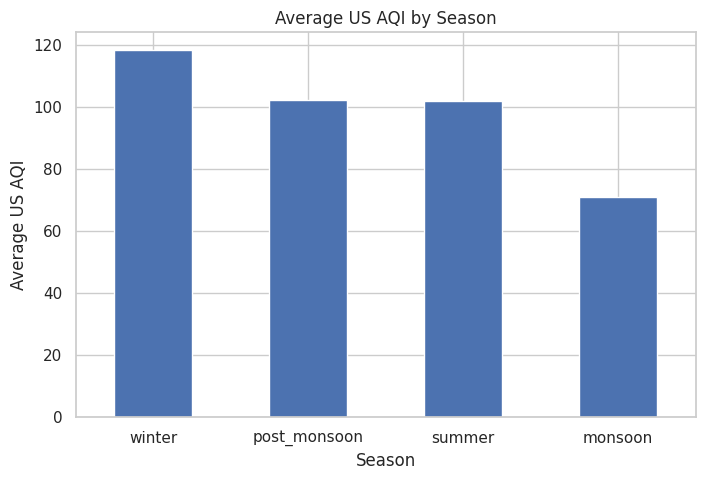

In [ ]:
season_aqi = (
    df.groupby("season")["us_aqi"]
      .mean()
      .sort_values(ascending=False)
)

display(season_aqi.to_frame("Average US AQI"))

plt.figure(figsize=(8, 5))
season_aqi.plot(kind="bar")
plt.title("Average US AQI by Season")
plt.xlabel("Season")
plt.ylabel("Average US AQI")
plt.xticks(rotation=0)
plt.show()


## 13. AQI Trend Over Time

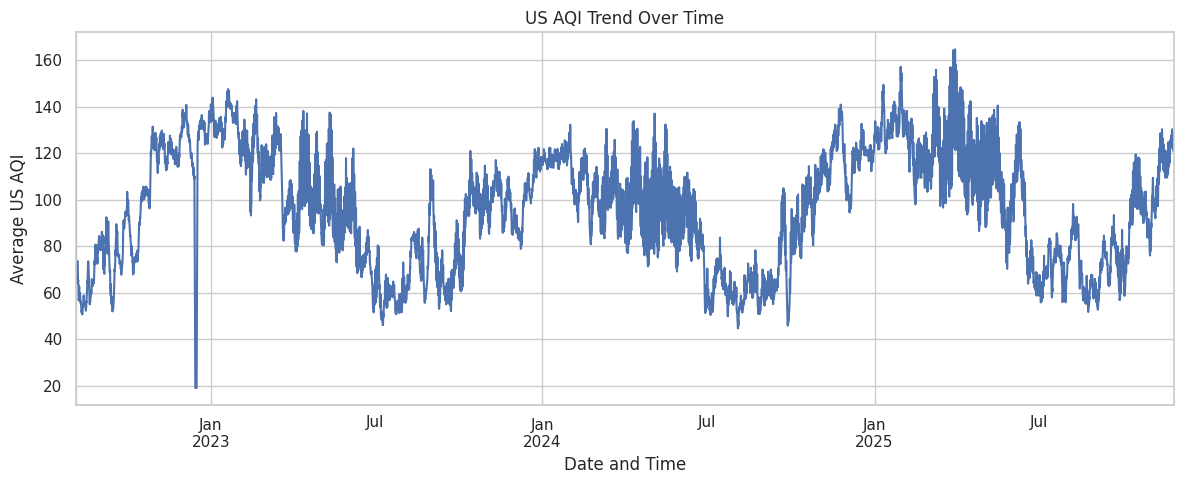

In [ ]:
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

daily_aqi = df.groupby("datetime")["us_aqi"].mean()

plt.figure(figsize=(12, 5))
daily_aqi.plot()

plt.title("US AQI Trend Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Average US AQI")
plt.tight_layout()
plt.show()


## 14. AQI by Month

,Average US AQI
month,
1.0,128.408077
2.0,113.648834
3.0,108.920313
4.0,101.475287
5.0,95.371462
6.0,83.625335
7.0,62.896011
8.0,67.103784
9.0,70.608645


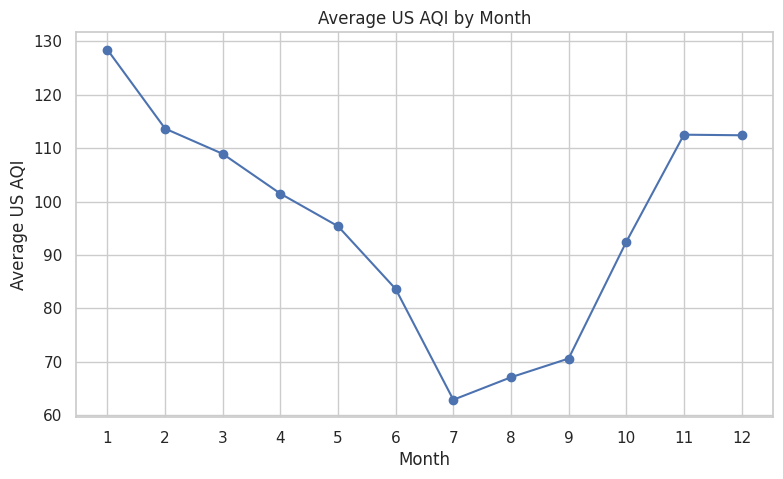

In [ ]:
monthly_aqi = (
    df.groupby("month")["us_aqi"]
      .mean()
      .sort_index()
)

display(monthly_aqi.to_frame("Average US AQI"))

plt.figure(figsize=(9, 5))
monthly_aqi.plot(kind="line", marker="o")

plt.title("Average US AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average US AQI")
plt.xticks(range(1, 13))
plt.show()


## 15. AQI by Time of Day

,Average US AQI
time_of_day,
evening,100.882645
afternoon,96.846082
night_late,95.222998
night,92.477130
morning,92.288330
early_morning,92.176309


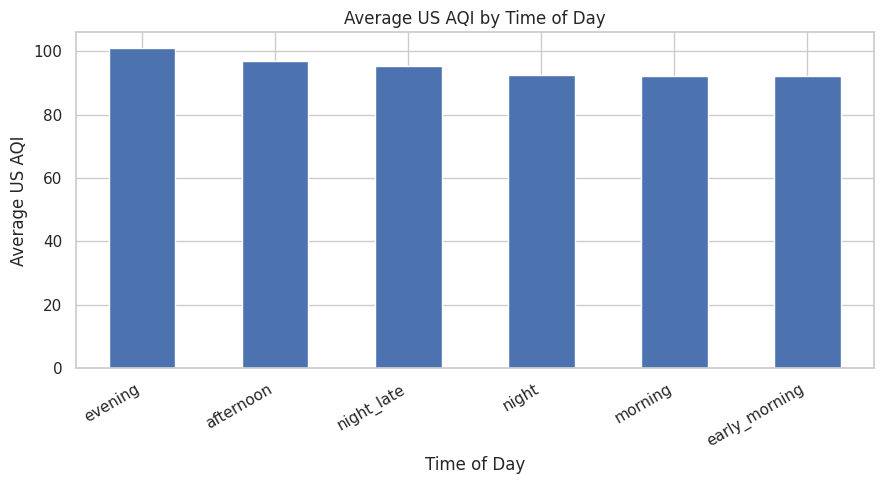

In [ ]:
time_aqi = (
    df.groupby("time_of_day")["us_aqi"]
      .mean()
      .sort_values(ascending=False)
)

display(time_aqi.to_frame("Average US AQI"))

plt.figure(figsize=(9, 5))
time_aqi.plot(kind="bar")

plt.title("Average US AQI by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Average US AQI")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Week 4 Final Summary

### Completed:
- Dataset inspection
- Missing-value check
- **Univariate analysis**
- AQI histogram
- AQI boxplot
- Pollutant distributions
- **Bivariate analysis**
- AQI vs pollutant scatterplots
- Correlation heatmap
- City-wise AQI comparison
- Seasonal AQI comparison
- AQI trend over time
- Monthly AQI analysis
- Time-of-day AQI analysis

### Presentation statement

> **“In Week 4, we performed Exploratory Data Analysis using univariate and bivariate techniques. We analyzed AQI and pollutant distributions, studied relationships using scatterplots and correlation, compared AQI across cities and seasons, and examined changes over time.”**
